# Iris Flower Classification

## 1.  Introduction

The objective of this project is to build a machine learning model that classifies Iris flowers into their respective species based on sepal and petal measurements.

## 2. Dataset Loading and Initial Inspection

### 2.1 Importing Required Libraries

In [1]:
import pandas as pd

### 2.2 Loading the Dataset

In [2]:
df = pd.read_csv("../data/iris.csv")

### 2.3 Previewing the Dataset

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### 2.4 Understanding Dataset Structure

In [4]:
df.shape

(150, 6)

In [5]:
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


### 2.5 Initial Dataset Overview

- The dataset contains 150 rows and 6 columns.
- It includes four numerical measurement features: SepalLengthCm, SepalWidthCm, PetalLengthCm, and PetalWidthCm.
- The Species column contains the target labels used to classify Iris flowers.
- The Id column represents record identifiers and is not a biological measurement.
- All columns contain 150 non-null values. The dataset includes four floating-point columns, one integer column, and one object/string column representing the species labels.

## 3. Data Quality Checks

### 3.1 Checking for Missing Values

In [7]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

### 3.2 Checking for Duplicate Records

In [8]:
df.duplicated().sum()

np.int64(0)

### 3.3 Checking for Duplicate Flower Measurements

The `Id` column uniquely identifies each record, so two rows with identical flower measurements and species labels may not be detected as duplicates when the entire row is compared. To investigate this possibility, duplicate records are checked using the four numerical measurements and the species label, excluding `Id`.

This check helps identify potentially repeated flower records without automatically removing any observations.

In [9]:
# Define the columns used to identify duplicate flower records
measurement_columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm",
    "Species"
]

# Count duplicate records while excluding the Id column
duplicate_flowers = df.duplicated(
    subset=measurement_columns
).sum()

print(
    "Duplicate flower records excluding Id:",
    duplicate_flowers
)

Duplicate flower records excluding Id: 3


##### 3.3.1 Interpreting Duplicate Flower Records

The duplicate-measurement check identified **3 rows that repeat previously occurring combinations of flower measurements and species labels**, excluding the `Id` column.

The initial full-row duplicate check returned zero because the `Id` values distinguish the rows. However, identical measurements do not necessarily indicate data-entry errors, as different flowers can share the same measurements.

These records will be retained because the available information does not establish that they are erroneous. No rows were removed during this data quality assessment.

### 3.4 Analyzing Species Distribution

In [10]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [11]:
df["Species"].value_counts(normalize=True) * 100

Species
Iris-setosa        33.333333
Iris-versicolor    33.333333
Iris-virginica     33.333333
Name: proportion, dtype: float64

### 3.5 Data Quality Summary

* The dataset contains no missing values.
* No exact duplicate rows were found when all columns, including `Id`, were considered.
* Three duplicate flower records were identified when the `Id` column was excluded from the comparison.
* All three Iris species have equal representation, with 50 observations per species.
* No rows were removed during the initial data quality checks.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Descriptive Statistics

In [12]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


### 4.2 Species-Wise Mean Feature Comparison

In [13]:
df.groupby("Species")[[
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]].mean().round(2)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Species,,,,
Iris-setosa,5.01,3.42,1.46,0.24
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03


## 5. Data Visualization

### 5.1 Importing Visualization Libraries

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

### 5.2 Petal Length Distribution by Species

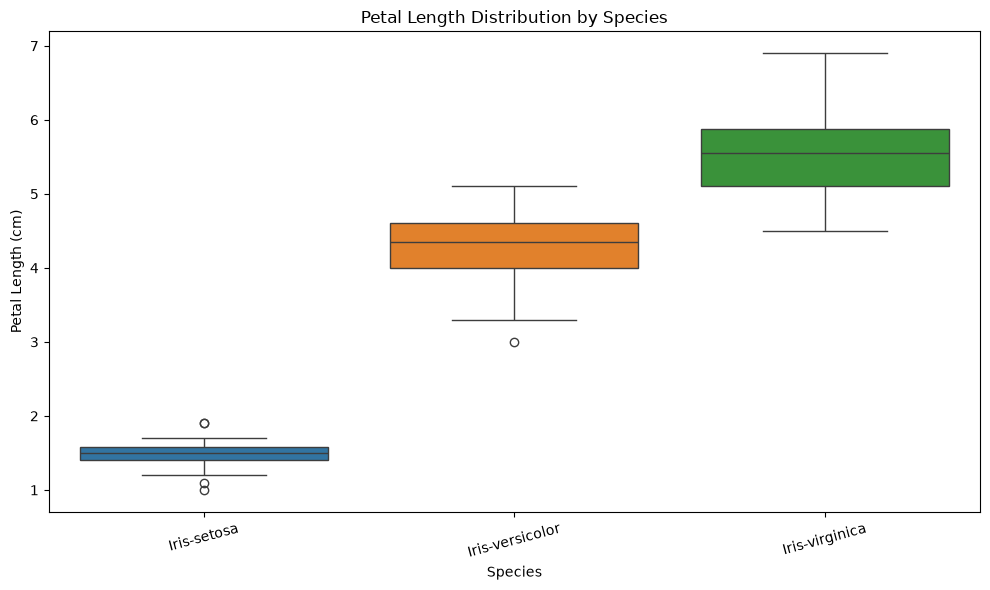

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Species",
    y="PetalLengthCm",
    hue="Species",
    legend=False
)

plt.title("Petal Length Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Petal Length (cm)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 5.3 Feature Distribution Comparison Across Species

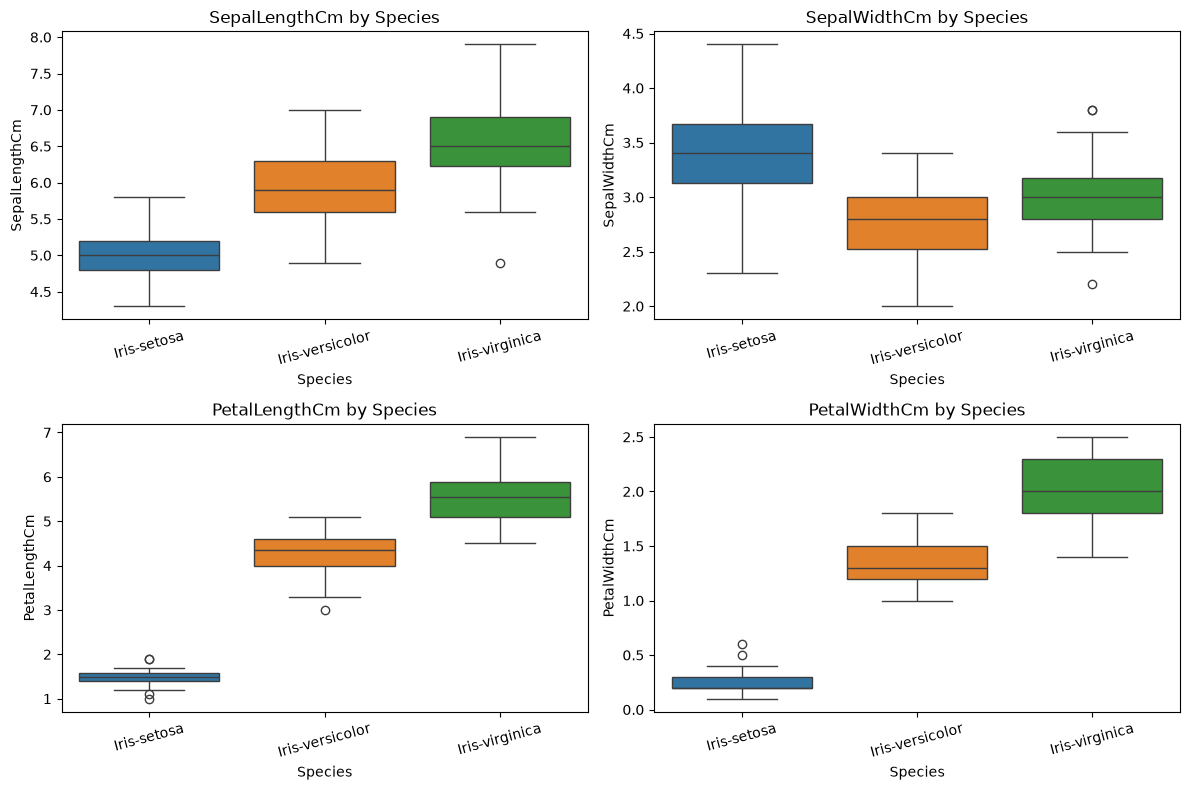

In [16]:
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(
        data=df,
        x="Species",
        y=feature,
        hue="Species",
        legend=False,
        ax=ax
    )
    ax.set_title(f"{feature} by Species")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### 5.4 Visualization Findings

- Petal length and petal width show clear differences among the three Iris species.
- Iris-setosa has noticeably smaller petals than the other two species.
- Sepal measurements show more overlap between species.
- A few observations appear as potential outliers in some box plots. These will be retained for now because there is no evidence that they are incorrect.
- Petal measurements appear promising for building a classification model.

## 6. Feature Relationships

### 6.1 Relationship Between Petal Length and Petal Width

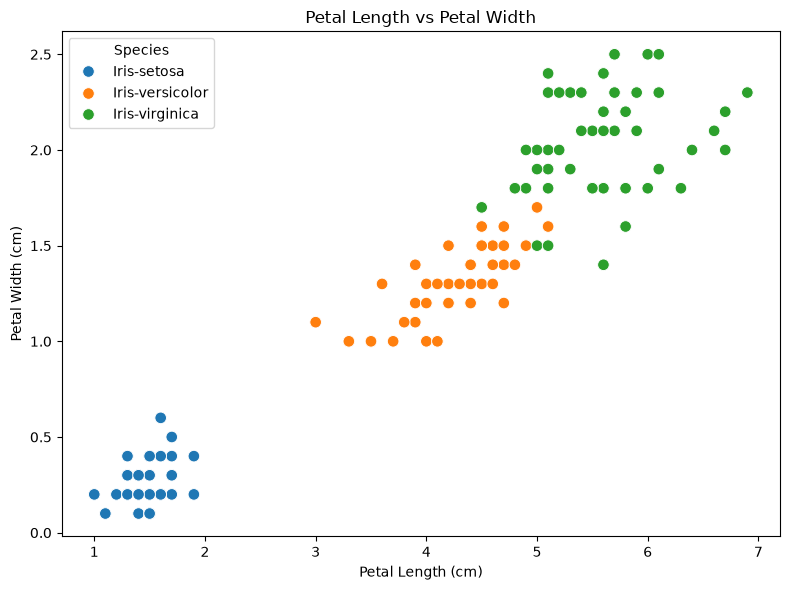

In [17]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    s=70
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

### 6.2 Petal Length vs Petal Width - Findings

- Petal length and petal width show a positive relationship: flowers with longer petals generally have wider petals.
- Iris-setosa forms a clearly separated cluster with relatively small petal measurements.
- Iris-versicolor generally occupies the middle range of petal length and width.
- Iris-virginica generally has larger petal measurements than the other two species.
- Some overlap exists between Iris-versicolor and Iris-virginica, suggesting that distinguishing these species may be more challenging.
- Overall, petal length and petal width appear to be useful features for Iris species classification.

These observations will be investigated further using correlation analysis and machine learning.

### 6.3 Correlation Analysis of Numerical Features

In [18]:
# Select the four numerical flower measurements
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

# Calculate the correlation matrix
correlation_matrix = df[features].corr()

# Display the results
correlation_matrix.round(2)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
SepalLengthCm,1.00,-0.11,0.87,0.82
SepalWidthCm,-0.11,1.00,-0.42,-0.36
PetalLengthCm,0.87,-0.42,1.00,0.96
PetalWidthCm,0.82,-0.36,0.96,1.00


### 6.4 Interpretation of the Correlation Matrix

The correlation matrix measures the strength and direction of the linear relationships between the four numerical features. Correlation coefficients range from -1 to +1, where positive values indicate that two features tend to increase together, while negative values indicate an inverse relationship.

The following observations can be made from the correlation matrix:

1. **Petal Length and Petal Width (0.96):** These features have a very strong positive correlation, indicating that flowers with longer petals generally tend to have wider petals.

2. **Sepal Length and Petal Length (0.87):** These features have a strong positive correlation, suggesting that flowers with longer sepals tend to have longer petals.

3. **Sepal Length and Petal Width (0.82):** This strong positive correlation indicates that longer sepals tend to be associated with wider petals.

4. **Sepal Width and Petal Length (-0.42):** These features have a moderate negative correlation, suggesting that larger petal lengths tend to be associated with smaller sepal widths across the dataset.

5. **Sepal Width and Petal Width (-0.36):** This negative correlation indicates a weak-to-moderate inverse relationship between the two features.

6. **Sepal Length and Sepal Width (-0.11):** These features have a very weak negative linear relationship.

#### Correlation Analysis - Findings

* Petal length and petal width have the strongest positive correlation (0.96).
* Sepal length is strongly positively correlated with both petal length (0.87) and petal width (0.82).
* Sepal width has negative correlations with both petal length (-0.42) and petal width (-0.36).
* Sepal length and sepal width have a very weak negative correlation (-0.11).
* Overall, the correlation analysis suggests that petal measurements may provide useful information for distinguishing Iris species.

**Note:** Correlation does not imply causation. These correlations are calculated across all three Iris species, so some relationships may reflect differences between species. The usefulness of these features will be evaluated further during model development.

### 6.5 Correlation Heatmap

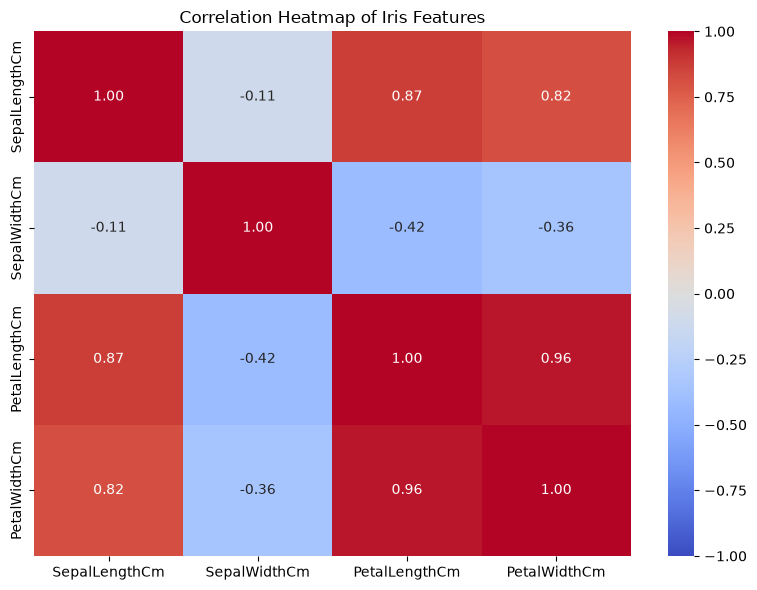

In [19]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Iris Features")
plt.tight_layout()
plt.show()

#### Heatmap Interpretation

The correlation heatmap provides a visual representation of the relationships between the numerical features.

* Petal length and petal width show the strongest positive correlation (0.96), represented by a strong positive colour.
* Sepal length also shows strong positive correlations with petal length (0.87) and petal width (0.82).
* Sepal width has negative correlations with petal length (-0.42) and petal width (-0.36).
* Sepal length and sepal width show a very weak negative correlation (-0.11).

The heatmap confirms the relationships identified in the correlation matrix. These observations suggest that petal measurements may be useful predictors for classifying Iris species.

## 7. Preparing the Data for Machine Learning

Before training a classification model, the dataset must be divided into input features and a target variable.

The four numerical flower measurements will be used as input features (`X`), while `Species` will be the target variable (`y`). The `Id` column will be excluded because it identifies records rather than describing flower characteristics.

### 7.1 Defining Features and Target Variable

In [20]:
# Define the input features
X = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

# Define the target variable
y = df["Species"]

# Inspect the dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Preview the features and target
display(X.head())
display(y.head())

Features shape: (150, 4)
Target shape: (150,)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: str

### 7.2 Splitting the Dataset

The dataset will be divided into training and testing subsets using an 80/20 split. The training set will be used to fit the classification model, while the testing set will be reserved for evaluating its performance on unseen observations.

A fixed random state ensures reproducibility, and stratified sampling maintains the class distribution of the three Iris species in both subsets.

In [21]:
from sklearn.model_selection import train_test_split

# Split the features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the dimensions of each subset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check species distribution in each subset
print("\nTraining species distribution:")
print(y_train.value_counts())

print("\nTesting species distribution:")
print(y_test.value_counts())

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)

Training species distribution:
Species
Iris-setosa        40
Iris-virginica     40
Iris-versicolor    40
Name: count, dtype: int64

Testing species distribution:
Species
Iris-setosa        10
Iris-virginica     10
Iris-versicolor    10
Name: count, dtype: int64


## 8. Building the Classification Model

### 8.1 K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised classification algorithm that predicts the class of a new observation based on the classes of its nearest observations in the training dataset.

The initial model will use five nearest neighbors. Because KNN depends on distances between observations, the numerical features will be standardized before classification. A scikit-learn pipeline will ensure that preprocessing is fitted using only the training data.

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create a pipeline for scaling and classification
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

# Train the model using only the training data
knn_model.fit(X_train, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


### 8.2 Making Predictions

After training the K-Nearest Neighbors classifier, predictions will be generated for the test dataset. These predictions will be compared with the actual species labels to assess how well the model generalizes to unseen observations.

In [23]:
# Predict species for the test observations
y_pred = knn_model.predict(X_test)

# Compare actual and predicted species
comparison = pd.DataFrame({
    "Actual Species": y_test,
    "Predicted Species": y_pred
})

display(comparison)

,Actual Species,Predicted Species
38,Iris-setosa,Iris-setosa
127,Iris-virginica,Iris-virginica
57,Iris-versicolor,Iris-versicolor
93,Iris-versicolor,Iris-versicolor
42,Iris-setosa,Iris-setosa
56,Iris-versicolor,Iris-versicolor
22,Iris-setosa,Iris-setosa
20,Iris-setosa,Iris-setosa
147,Iris-virginica,Iris-virginica
84,Iris-versicolor,Iris-versicolor


### 8.3 Evaluating Model Accuracy

Accuracy measures the proportion of test observations for which the model correctly predicts the Iris species. It provides an initial summary of classification performance, although it does not show which species are most frequently misclassified.

In [24]:
from sklearn.metrics import accuracy_score

# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.2%}")

Test Accuracy: 93.33%


### 8.4 Classification Report

The classification report evaluates model performance separately for each Iris species using precision, recall, and F1-score. Support indicates the number of actual test observations for each species.

These metrics provide a more detailed assessment than accuracy alone, helping identify whether the classifier performs better for some species than others.

In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



### 8.5 Confusion Matrix

A confusion matrix compares the actual species labels with the model's predictions. Correct predictions appear along the main diagonal, while values outside the diagonal represent misclassifications.

This visualization helps identify which Iris species the classifier confuses with one another.

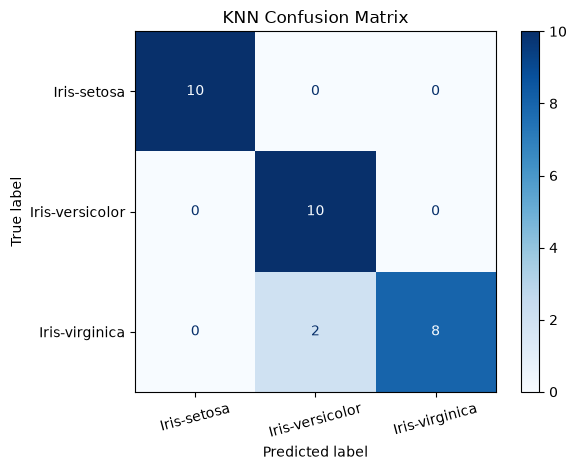

Confusion matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define a consistent class order
class_names = [
    "Iris-setosa",
    "Iris-versicolor",
    "Iris-virginica"
]

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_names
)

# Display the confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("KNN Confusion Matrix")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Print the matrix values
print("Confusion matrix:")
print(cm)

### Confusion Matrix - Findings

- The model correctly classified all 10 Iris-setosa observations.
- All 10 Iris-versicolor observations were correctly classified.
- Of the 10 Iris-virginica observations, 8 were correctly classified and 2 were misclassified as Iris-versicolor.
- No setosa or versicolor observations were misclassified as another species.
- The confusion matrix confirms the test accuracy of 93.33% (28 correct predictions out of 30).

The results indicate that the KNN model distinguishes Iris-setosa effectively but has some difficulty separating Iris-virginica from Iris-versicolor. This is consistent with the overlap between these species observed during exploratory data analysis.

## 9. Comparing Classification Models

### 9.1 Decision Tree Classifier

A Decision Tree is a supervised learning algorithm that classifies observations by learning decision rules based on their feature values. It repeatedly divides the data into groups to improve class separation.

A Decision Tree will be trained and evaluated using the same training and testing sets as the KNN model. Comparing both models will help determine how their predictive performance differs on this dataset.

In [27]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(random_state=42)

# Train the model
tree_model.fit(X_train, y_train)

# Predict species for the test set
tree_pred = tree_model.predict(X_test)

# Evaluate test accuracy
tree_accuracy = accuracy_score(y_test, tree_pred)

print(f"KNN Test Accuracy: {accuracy:.2%}")
print(f"Decision Tree Test Accuracy: {tree_accuracy:.2%}")

KNN Test Accuracy: 93.33%
Decision Tree Test Accuracy: 93.33%


### 9.2 Comparing Model Performance

The K-Nearest Neighbors (KNN) and Decision Tree classifiers were evaluated using the same training and testing datasets. Their performance is compared using test accuracy, the number of correct predictions, and the number of incorrect predictions.

Test accuracy measures the proportion of test observations classified correctly. Comparing the number of correct and incorrect predictions provides a simple overview of each model's performance before examining class-specific metrics and confusion matrices.

In [28]:
from sklearn.metrics import accuracy_score
import pandas as pd

# Count correct and incorrect predictions for each model
knn_correct = (y_test == y_pred).sum()
tree_correct = (y_test == tree_pred).sum()

total_test_samples = len(y_test)

# Create a model comparison table
model_comparison = pd.DataFrame({
    "Model": ["KNN", "Decision Tree"],
    "Test Accuracy": [accuracy, tree_accuracy],
    "Correct Predictions": [knn_correct, tree_correct],
    "Incorrect Predictions": [
        total_test_samples - knn_correct,
        total_test_samples - tree_correct
    ]
})

# Format accuracy as percentages
model_comparison["Test Accuracy"] = (
    model_comparison["Test Accuracy"] * 100
).map(lambda value: f"{value:.2f}%")

display(model_comparison)

,Model,Test Accuracy,Correct Predictions,Incorrect Predictions
0,KNN,93.33%,28,2
1,Decision Tree,93.33%,28,2


#### Model Performance Comparison - Findings

- Both KNN and Decision Tree achieved a test accuracy of 93.33%.
- Each model correctly classified 28 out of 30 test observations and misclassified 2.
- Neither model outperformed the other in overall accuracy on this test set.
- The classification reports and confusion matrices provide further insight into class-specific performance and reveal differences in the misclassification patterns of the two models.

### 9.3 Comparing Classification Reports

The classification reports for KNN and Decision Tree will be compared using precision, recall, F1-score, and support for each Iris species. Although both models achieved the same overall test accuracy, their class-specific metrics may reveal differences in how they classify individual species.

In [29]:
from sklearn.metrics import classification_report

# Classification report for KNN
print("KNN Classification Report")
print(classification_report(y_test, y_pred))

# Classification report for Decision Tree
print("\nDecision Tree Classification Report")
print(classification_report(y_test, tree_pred))

KNN Classification Report
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30


Decision Tree Classification Report
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



#### Classification Report - Findings

- Both KNN and Decision Tree achieved a test accuracy of 93.33%.
- Both models classified all Iris-setosa test observations correctly, achieving precision, recall, and F1-scores of 1.00.
- KNN achieved perfect recall for Iris-versicolor but lower precision (0.83), indicating that some predictions of versicolor belonged to another species.
- For Iris-virginica, KNN achieved perfect precision (1.00) but lower recall (0.80), meaning that two actual virginica observations were misclassified.
- Decision Tree achieved precision and recall of 0.90 for both versicolor and virginica, providing a more balanced result for these classes.
- These findings demonstrate that models with equal overall accuracy can differ in their class-specific performance.

The confusion matrices will be examined next to verify the exact misclassification patterns of both models.

### 9.4 Comparing Confusion Matrices

A confusion matrix shows how many observations from each actual class were assigned to each predicted class. It helps identify which species a model confuses with another.

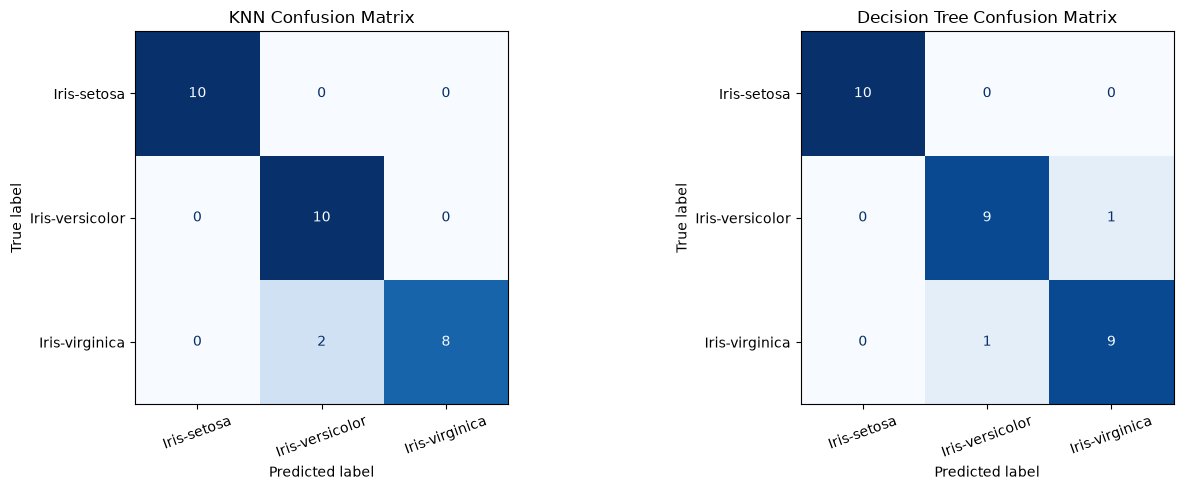

KNN Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Decision Tree Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Keep the class order consistent across both models
class_names = [
    "Iris-setosa",
    "Iris-versicolor",
    "Iris-virginica"
]

# Calculate confusion matrices
knn_cm = confusion_matrix(
    y_test, y_pred, labels=class_names
)

tree_cm = confusion_matrix(
    y_test, tree_pred, labels=class_names
)

# Display both matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=class_names
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("KNN Confusion Matrix")
axes[0].tick_params(axis="x", rotation=20)

ConfusionMatrixDisplay(
    confusion_matrix=tree_cm,
    display_labels=class_names
).plot(
    ax=axes[1],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[1].set_title("Decision Tree Confusion Matrix")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

# Print the exact values for interpretation
print("KNN Confusion Matrix:")
print(knn_cm)

print("\nDecision Tree Confusion Matrix:")
print(tree_cm)

#### Confusion Matrix - Findings

- Both KNN and Decision Tree correctly classified all 10 Iris-setosa test samples.
- KNN correctly classified all 10 Iris-versicolor samples but misclassified 2 Iris-virginica samples as Iris-versicolor.
- Decision Tree correctly classified 9 of 10 Iris-versicolor samples and 9 of 10 Iris-virginica samples. It confused one sample in each direction between these two species.
- Both models correctly classified 28 out of 30 test samples, achieving the same test accuracy of 93.33%.
- Although their overall accuracy was identical, their error patterns differed. KNN performed better on Iris-versicolor, while Decision Tree classified Iris-virginica more accurately on this test set.
- Neither model misclassified any Iris-setosa samples, suggesting that this species was clearly distinguishable in the selected test data.

These results show why confusion matrices complement accuracy: they reveal which classes contribute to a model's errors and help distinguish models with identical overall performance.

## 10. Conclusion

### 10.1 Project Summary

This project explored the Iris flower dataset and developed machine learning models to classify iris flowers into three species: Iris-setosa, Iris-versicolor, and Iris-virginica.

The dataset contained 150 observations with four numerical features: sepal length, sepal width, petal length, and petal width. Initial data quality checks found no missing values or exact duplicate rows when all columns were considered. An additional check identified three rows with repeated flower measurement and species combinations when the `Id` column was excluded. All three species were equally represented, with 50 observations each. No records were removed during the initial data quality assessment.

Exploratory data analysis, including summary statistics, boxplots, scatter plots, and a correlation heatmap, helped examine feature distributions and relationships. Petal length and petal width showed a strong positive correlation, while the visualizations indicated that the three species were not equally easy to distinguish.

Two classification models were trained and evaluated: K-Nearest Neighbors (KNN) and Decision Tree. The dataset was split into training and testing sets using an 80:20 ratio, with stratification to preserve the species proportions. The KNN model used feature standardization as part of a pipeline, while the Decision Tree was trained using its default classification settings and a fixed random seed.

### 10.2 Key Findings

Both models achieved **93.33% test accuracy**, correctly classifying 28 of the 30 test observations.

- **KNN:** Correctly classified all Iris-setosa and Iris-versicolor test samples. It misclassified two Iris-virginica samples as Iris-versicolor.
- **Decision Tree:** Correctly classified all Iris-setosa samples and nine samples each from Iris-versicolor and Iris-virginica. It misclassified one versicolor sample as virginica and one virginica sample as versicolor.
- **Feature relationships:** Petal length and petal width had a strong positive correlation of approximately 0.96 across the dataset.
- **Class-specific performance:** Both models classified Iris-setosa perfectly on the test set, while the remaining errors involved confusion between Iris-versicolor and Iris-virginica.

Although both models achieved the same overall accuracy, their confusion matrices revealed different error patterns. KNN performed better on Iris-versicolor in this test set, while Decision Tree correctly classified more Iris-virginica samples.

### 10.3 Limitations and Future Improvements

This project provides an initial comparison of two classification algorithms, but several limitations should be considered.

- **Small test set:** The test set contained only 30 observations, so the evaluation results may vary with a different train-test split.
- **Limited model selection:** Only KNN and Decision Tree were compared. Other algorithms, such as Logistic Regression, Support Vector Machine (SVM), and Random Forest, could also be evaluated.
- **Limited hyperparameter tuning:** The KNN model used five neighbors, and the Decision Tree used default hyperparameters. Systematic tuning could improve performance.
- **Single evaluation split:** Cross-validation could provide a more robust estimate of model performance across different data partitions.
- **Dataset scope:** Results from this dataset may not generalize to every iris flower population or real-world measurement setting.

Future work could include stratified cross-validation, hyperparameter tuning, additional classification algorithms, and a more systematic comparison using precision, recall, F1-score, and confusion matrices.

### 10.4 Final Takeaway

This project demonstrated an end-to-end introductory machine learning workflow, from data inspection and exploratory analysis to model training, prediction, and evaluation.

Both KNN and Decision Tree achieved 93.33% accuracy on the held-out test set. The comparison also demonstrated that overall accuracy alone does not fully describe model behavior: classification reports and confusion matrices are useful for identifying class-specific strengths and weaknesses.

The project strengthened practical skills in Python, pandas, data visualization, scikit-learn pipelines, classification algorithms, and model evaluation. It also highlighted the importance of validating model performance carefully and interpreting results in the context of the dataset and evaluation method.